# Proof of Theorem 3.2 — Reference Document

**Reduction from Steiner Tree to Metric Steiner Tree** (Vazirani, Chapter 3)

All text below is **copyable**. SVG images have **white backgrounds** for slides.

---

## 1. Problem Setup — Instance I

**Given:** Instance $I = (G, R, \text{cost})$

- **Graph:** $G = (V, E)$ with $V = \{a, b, c, d\}$
- **Required vertices:** $R = \{a, c, d\}$
- **Steiner vertices:** $\{b\}$
- **Number of edges:** 5 (no direct edge between a and d)

### Edge List

| Edge | From | To | Cost | Type |
|------|------|----|------|------|
| e1 | a | b | **3** | Required — Steiner |
| e2 | b | c | **2** | Steiner — Required |
| e3 | b | d | **4** | Steiner — Required |
| e4 | a | c | **7** | Required — Required |
| e5 | c | d | **8** | Required — Required |
| — | a | d | inf | No direct edge |

In [13]:
from IPython.display import SVG, display, HTML

# --- Color scheme for WHITE background ---
BLUE    = "#2563eb"   # Required vertices
GRAY    = "#64748b"   # Steiner vertices
GREEN   = "#16a34a"   # Metric closure / final tree
RED     = "#dc2626"   # Approximate solution
ORANGE  = "#d97706"   # Cost labels
PURPLE  = "#9333ea"   # Conclusion / pipeline
MUTED   = "#6b7280"   # Annotations
EDGE    = "#94a3b8"   # Edge lines
FONT    = "'Segoe UI', system-ui, sans-serif"
BG      = "#ffffff"

def wrap_svg(inner, w, h, extra_defs=""):
    return f'''<svg xmlns="http://www.w3.org/2000/svg" width="{w}" height="{h}" viewBox="0 0 {w} {h}" style="background:white">
<style>svg {{ font-family: {FONT}; }} text {{ font-family: {FONT}; }}</style>
<rect width="{w}" height="{h}" fill="{BG}" rx="8"/>
{extra_defs}
{inner}
</svg>'''

print("SVG helper ready. White background for all diagrams.")

SVG helper ready. White background for all diagrams.


### SVG 1 — Original Graph G

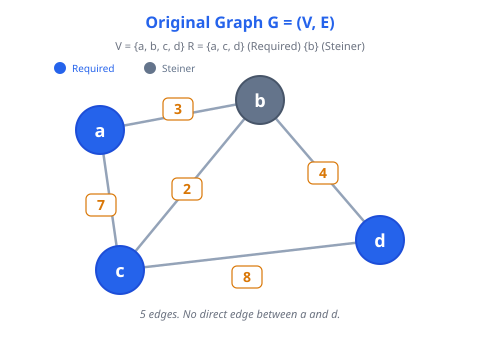

In [14]:
# SVG 1: Original Graph G
svg1 = wrap_svg('''
<text x="240" y="28" font-size="16" fill="#2563eb" text-anchor="middle" font-weight="700">Original Graph G = (V, E)</text>
<text x="240" y="50" font-size="11" fill="#6b7280" text-anchor="middle">V = {a, b, c, d}   R = {a, c, d} (Required)   {b} (Steiner)</text>

<!-- Legend -->
<circle cx="60" cy="68" r="6" fill="#2563eb"/>
<text x="72" y="72" font-size="10" fill="#2563eb">Required</text>
<circle cx="150" cy="68" r="6" fill="#64748b"/>
<text x="162" y="72" font-size="10" fill="#64748b">Steiner</text>

<!-- Edges -->
<line x1="100" y1="130" x2="260" y2="100" stroke="#94a3b8" stroke-width="2.5"/>
<line x1="260" y1="100" x2="120" y2="270" stroke="#94a3b8" stroke-width="2.5"/>
<line x1="260" y1="100" x2="380" y2="240" stroke="#94a3b8" stroke-width="2.5"/>
<line x1="100" y1="130" x2="120" y2="270" stroke="#94a3b8" stroke-width="2.5"/>
<line x1="120" y1="270" x2="380" y2="240" stroke="#94a3b8" stroke-width="2.5"/>

<!-- Cost labels -->
<rect x="163" y="98" width="30" height="22" rx="5" fill="#fff" stroke="#d97706" stroke-width="1.2"/>
<text x="178" y="114" font-size="14" fill="#d97706" text-anchor="middle" font-weight="700">3</text>
<rect x="172" y="178" width="30" height="22" rx="5" fill="#fff" stroke="#d97706" stroke-width="1.2"/>
<text x="187" y="194" font-size="14" fill="#d97706" text-anchor="middle" font-weight="700">2</text>
<rect x="308" y="162" width="30" height="22" rx="5" fill="#fff" stroke="#d97706" stroke-width="1.2"/>
<text x="323" y="178" font-size="14" fill="#d97706" text-anchor="middle" font-weight="700">4</text>
<rect x="86" y="194" width="30" height="22" rx="5" fill="#fff" stroke="#d97706" stroke-width="1.2"/>
<text x="101" y="210" font-size="14" fill="#d97706" text-anchor="middle" font-weight="700">7</text>
<rect x="232" y="266" width="30" height="22" rx="5" fill="#fff" stroke="#d97706" stroke-width="1.2"/>
<text x="247" y="282" font-size="14" fill="#d97706" text-anchor="middle" font-weight="700">8</text>

<!-- Vertices -->
<circle cx="100" cy="130" r="24" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="100" y="137" font-size="18" fill="#fff" text-anchor="middle" font-weight="700">a</text>
<circle cx="260" cy="100" r="24" fill="#64748b" stroke="#475569" stroke-width="2"/>
<text x="260" y="107" font-size="18" fill="#fff" text-anchor="middle" font-weight="700">b</text>
<circle cx="120" cy="270" r="24" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="120" y="277" font-size="18" fill="#fff" text-anchor="middle" font-weight="700">c</text>
<circle cx="380" cy="240" r="24" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="380" y="247" font-size="18" fill="#fff" text-anchor="middle" font-weight="700">d</text>

<text x="240" y="318" font-size="11" fill="#6b7280" text-anchor="middle" font-style="italic">5 edges. No direct edge between a and d.</text>
''', 480, 340)

display(SVG(svg1))

---

## 2. Construction: Metric Closure G'

**Rule:** Let $G'$ be the **complete graph** on $V$. Define $\text{cost}'(u,v)$ = shortest $u$-$v$ path distance in $G$.

We compute $\binom{4}{2} = 6$ pairs:

### All-Pairs Shortest Paths

| Pair | Direct Edge Cost | Best Alternative Path | cost' (shortest) | Changed? |
|------|-----------------|----------------------|-------------------|----------|
| **(a, b)** | 3 | Via c: a-c-b = 7+2 = 9 | **3** | No |
| **(a, c)** | 7 | Via b: a-b-c = 3+2 = **5** | **5** | Yes, shorter! |
| **(a, d)** | no edge | Via b: a-b-d = 3+4 = **7** | **7** | New edge! |
| **(b, c)** | 2 | Via a: b-a-c = 3+7 = 10 | **2** | No |
| **(b, d)** | 4 | Via c: b-c-d = 2+8 = 10 | **4** | No |
| **(c, d)** | 8 | Via b: c-b-d = 2+4 = **6** | **6** | Yes, shorter! |

### Result: Metric Closure G'

G' has **6 edges** (complete). Changes from G:
- **a-c:** cost 7 -> cost' = **5** (via b: 3+2)
- **a-d:** no edge -> cost' = **7** (new! via b: 3+4)
- **c-d:** cost 8 -> cost' = **6** (via b: 2+4)
- a-b, b-c, b-d: unchanged (3, 2, 4)

**Key property:** Triangle inequality holds: $\text{cost}'(u,w) \leq \text{cost}'(u,v) + \text{cost}'(v,w)$

Required vertices stay the same: $R' = R = \{a, c, d\}$

### Complete Edge Table for G'

| Edge | cost' in G' | Original cost in G | Shortest Path in G |
|------|-------------|-------------------|-------------------|
| a-b | **3** | 3 | direct |
| a-c | **5** | 7 | a -> b -> c |
| a-d | **7** | inf (no edge) | a -> b -> d |
| b-c | **2** | 2 | direct |
| b-d | **4** | 4 | direct |
| c-d | **6** | 8 | c -> b -> d |

### SVG 2 — G to G' Transformation

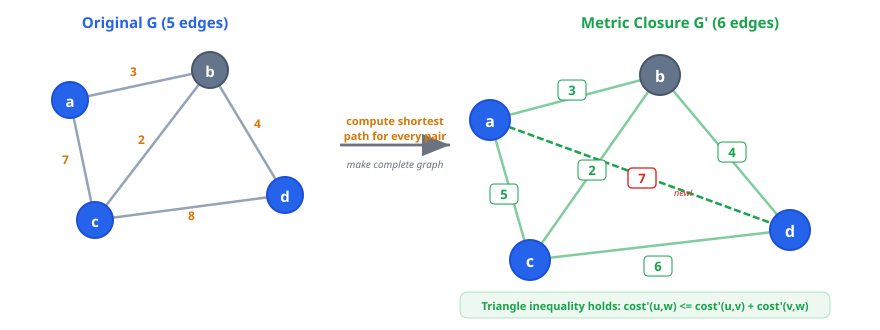

In [15]:
# SVG 2: G -> G' Transformation (side by side)
defs2 = '''<defs>
<marker id="arr" markerWidth="12" markerHeight="10" refX="10" refY="4" orient="auto"><path d="M0,0 L0,8 L10,4 z" fill="#6b7280"/></marker>
</defs>'''

svg2 = wrap_svg('''
<!-- LEFT: Original G -->
<text x="155" y="28" font-size="15" fill="#2563eb" text-anchor="middle" font-weight="700">Original G (5 edges)</text>
<line x1="70" y1="100" x2="210" y2="70" stroke="#94a3b8" stroke-width="2.5"/>
<line x1="210" y1="70" x2="95" y2="220" stroke="#94a3b8" stroke-width="2.5"/>
<line x1="210" y1="70" x2="285" y2="195" stroke="#94a3b8" stroke-width="2.5"/>
<line x1="70" y1="100" x2="95" y2="220" stroke="#94a3b8" stroke-width="2.5"/>
<line x1="95" y1="220" x2="285" y2="195" stroke="#94a3b8" stroke-width="2.5"/>
<text x="130" y="76" font-size="12" fill="#d97706" font-weight="700">3</text>
<text x="138" y="144" font-size="12" fill="#d97706" font-weight="700">2</text>
<text x="254" y="128" font-size="12" fill="#d97706" font-weight="700">4</text>
<text x="62" y="164" font-size="12" fill="#d97706" font-weight="700">7</text>
<text x="188" y="220" font-size="12" fill="#d97706" font-weight="700">8</text>
<circle cx="70" cy="100" r="18" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="70" y="107" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">a</text>
<circle cx="210" cy="70" r="18" fill="#64748b" stroke="#475569" stroke-width="2"/>
<text x="210" y="77" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">b</text>
<circle cx="95" cy="220" r="18" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="95" y="227" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">c</text>
<circle cx="285" cy="195" r="18" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="285" y="202" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">d</text>

<!-- Arrow -->
<line x1="340" y1="145" x2="450" y2="145" stroke="#6b7280" stroke-width="2.8" marker-end="url(#arr)"/>
<text x="395" y="125" font-size="11" fill="#d97706" text-anchor="middle" font-weight="600">compute shortest</text>
<text x="395" y="140" font-size="11" fill="#d97706" text-anchor="middle" font-weight="600">path for every pair</text>
<text x="395" y="168" font-size="10" fill="#6b7280" text-anchor="middle" font-style="italic">make complete graph</text>

<!-- RIGHT: G' complete -->
<text x="680" y="28" font-size="15" fill="#16a34a" text-anchor="middle" font-weight="700">Metric Closure G' (6 edges)</text>
<line x1="490" y1="120" x2="660" y2="75"  stroke="#16a34a" stroke-width="2.5" opacity=".55"/>
<line x1="490" y1="120" x2="530" y2="260" stroke="#16a34a" stroke-width="2.5" opacity=".55"/>
<line x1="490" y1="120" x2="790" y2="230" stroke="#16a34a" stroke-width="2.5" stroke-dasharray="7,3"/>
<line x1="660" y1="75"  x2="530" y2="260" stroke="#16a34a" stroke-width="2.5" opacity=".55"/>
<line x1="660" y1="75"  x2="790" y2="230" stroke="#16a34a" stroke-width="2.5" opacity=".55"/>
<line x1="530" y1="260" x2="790" y2="230" stroke="#16a34a" stroke-width="2.5" opacity=".55"/>

<!-- Cost labels G' -->
<rect x="558" y="80" width="28" height="20" rx="4" fill="#fff" stroke="#16a34a" stroke-width="1"/>
<text x="572" y="95" font-size="13" fill="#16a34a" text-anchor="middle" font-weight="700">3</text>
<rect x="490" y="184" width="28" height="20" rx="4" fill="#fff" stroke="#16a34a" stroke-width="1"/>
<text x="504" y="199" font-size="13" fill="#16a34a" text-anchor="middle" font-weight="700">5</text>
<rect x="628" y="168" width="28" height="20" rx="4" fill="#fff" stroke="#dc2626" stroke-width="1.4"/>
<text x="642" y="183" font-size="13" fill="#dc2626" text-anchor="middle" font-weight="700">7</text>
<text x="674" y="196" font-size="9" fill="#dc2626" font-style="italic">new!</text>
<rect x="578" y="160" width="28" height="20" rx="4" fill="#fff" stroke="#16a34a" stroke-width="1"/>
<text x="592" y="175" font-size="13" fill="#16a34a" text-anchor="middle" font-weight="700">2</text>
<rect x="718" y="142" width="28" height="20" rx="4" fill="#fff" stroke="#16a34a" stroke-width="1"/>
<text x="732" y="157" font-size="13" fill="#16a34a" text-anchor="middle" font-weight="700">4</text>
<rect x="644" y="256" width="28" height="20" rx="4" fill="#fff" stroke="#16a34a" stroke-width="1"/>
<text x="658" y="271" font-size="13" fill="#16a34a" text-anchor="middle" font-weight="700">6</text>

<!-- Vertices G' -->
<circle cx="490" cy="120" r="20" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="490" y="127" font-size="16" fill="#fff" text-anchor="middle" font-weight="700">a</text>
<circle cx="660" cy="75"  r="20" fill="#64748b" stroke="#475569" stroke-width="2"/>
<text x="660" y="82"  font-size="16" fill="#fff" text-anchor="middle" font-weight="700">b</text>
<circle cx="530" cy="260" r="20" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="530" y="267" font-size="16" fill="#fff" text-anchor="middle" font-weight="700">c</text>
<circle cx="790" cy="230" r="20" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="790" y="237" font-size="16" fill="#fff" text-anchor="middle" font-weight="700">d</text>

<!-- Bottom note -->
<rect x="460" y="292" width="370" height="26" rx="7" fill="rgba(22,163,74,.08)" stroke="rgba(22,163,74,.3)"/>
<text x="645" y="310" font-size="11" fill="#16a34a" text-anchor="middle" font-weight="600">Triangle inequality holds: cost'(u,w) &lt;= cost'(u,v) + cost'(v,w)</text>
''', 880, 330, defs2)

display(SVG(svg2))

---

## 3. Direction 1 — Lower Bound: OPT(I') <= OPT(I)

**Argument:** For any edge $(u,v) \in E$ of graph $G$, its cost in $G'$ is **at most** its cost in $G$, because the edge itself is one candidate shortest path.

Therefore: $\text{cost}'(u,v) \leq \text{cost}(u,v)$ for every edge $(u,v) \in E$

The optimal Steiner tree of $G$ can be placed into $G'$ with equal or lower total cost.

### Concrete Verification

| Tree | Location | Edges | Edge Costs | Total Cost |
|------|----------|-------|------------|------------|
| **OPT in G** | Original graph G | {a-b, b-c, b-d} | 3 + 2 + 4 | **9** |
| **Same tree in G'** | Metric closure G' | {a-b, b-c, b-d} | 3 + 2 + 4 | **9 <= 9** |

Each edge: cost'(a,b)=3 <= 3, cost'(b,c)=2 <= 2, cost'(b,d)=4 <= 4

$$OPT(I') \leq OPT(I)$$

### SVG 3 — OPT(I') <= OPT(I)

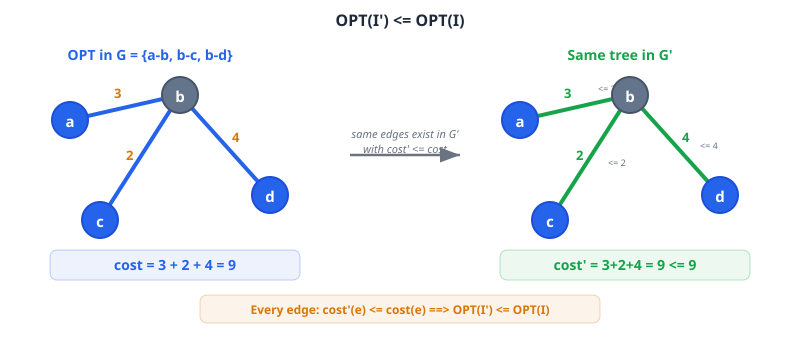

In [22]:
# SVG 3: OPT(I') <= OPT(I)  Lower Bound
defs3 = '<defs><marker id="a1" markerWidth="9" markerHeight="9" refX="8" refY="3" orient="auto"><path d="M0,0 L0,6 L8,3 z" fill="#6b7280"/></marker></defs>'

svg3 = wrap_svg('''
<text x="400" y="26" font-size="16" fill="#1e293b" text-anchor="middle" font-weight="700">OPT(I') &lt;= OPT(I)</text>

<!-- LEFT: OPT in G -->
<text x="150" y="60" font-size="14" fill="#2563eb" text-anchor="middle" font-weight="700">OPT in G = {a-b, b-c, b-d}</text>
<line x1="70" y1="120" x2="180" y2="95" stroke="#2563eb" stroke-width="4"/>
<line x1="180" y1="95" x2="100" y2="220" stroke="#2563eb" stroke-width="4"/>
<line x1="180" y1="95" x2="270" y2="195" stroke="#2563eb" stroke-width="4"/>
<text x="114" y="98" font-size="13" fill="#d97706" font-weight="700">3</text>
<text x="126" y="160" font-size="13" fill="#d97706" font-weight="700">2</text>
<text x="232" y="142" font-size="13" fill="#d97706" font-weight="700">4</text>
<circle cx="70" cy="120" r="18" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="70" y="127" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">a</text>
<circle cx="180" cy="95" r="18" fill="#64748b" stroke="#475569" stroke-width="2"/>
<text x="180" y="102" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">b</text>
<circle cx="100" cy="220" r="18" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="100" y="227" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">c</text>
<circle cx="270" cy="195" r="18" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="270" y="202" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">d</text>
<rect x="50" y="250" width="250" height="30" rx="7" fill="rgba(37,99,235,.08)" stroke="rgba(37,99,235,.3)"/>
<text x="175" y="270" font-size="14" fill="#2563eb" text-anchor="middle" font-weight="700">cost = 3 + 2 + 4 = 9</text>

<!-- Arrow -->
<line x1="350" y1="155" x2="460" y2="155" stroke="#6b7280" stroke-width="2.5" marker-end="url(#a1)"/>
<text x="405" y="138" font-size="11" fill="#6b7280" text-anchor="middle" font-style="italic">same edges exist in G'</text>
<text x="405" y="153" font-size="11" fill="#6b7280" text-anchor="middle" font-style="italic">with cost' &lt;= cost</text>

<!-- RIGHT: Same tree in G' -->
<text x="620" y="60" font-size="14" fill="#16a34a" text-anchor="middle" font-weight="700">Same tree in G'</text>
<line x1="520" y1="120" x2="630" y2="95" stroke="#16a34a" stroke-width="4"/>
<line x1="630" y1="95" x2="550" y2="220" stroke="#16a34a" stroke-width="4"/>
<line x1="630" y1="95" x2="720" y2="195" stroke="#16a34a" stroke-width="4"/>
<text x="564" y="98" font-size="13" fill="#16a34a" font-weight="700">3</text>
<text x="576" y="160" font-size="13" fill="#16a34a" font-weight="700">2</text>
<text x="682" y="142" font-size="13" fill="#16a34a" font-weight="700">4</text>
<text x="598" y="92" font-size="9" fill="#6b7280">&lt;= 3</text>
<text x="608" y="166" font-size="9" fill="#6b7280">&lt;= 2</text>
<text x="700" y="149" font-size="9" fill="#6b7280">&lt;= 4</text>
<circle cx="520" cy="120" r="18" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="520" y="127" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">a</text>
<circle cx="630" cy="95" r="18" fill="#64748b" stroke="#475569" stroke-width="2"/>
<text x="630" y="102" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">b</text>
<circle cx="550" cy="220" r="18" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="550" y="227" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">c</text>
<circle cx="720" cy="195" r="18" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text x="720" y="202" font-size="15" fill="#fff" text-anchor="middle" font-weight="700">d</text>
<rect x="500" y="250" width="250" height="30" rx="7" fill="rgba(22,163,74,.08)" stroke="rgba(22,163,74,.3)"/>
<text x="625" y="270" font-size="14" fill="#16a34a" text-anchor="middle" font-weight="700">cost' = 3+2+4 = 9 &lt;= 9</text>

<!-- Bottom -->
<rect x="200" y="295" width="400" height="28" rx="7" fill="rgba(217,119,6,.08)" stroke="rgba(217,119,6,.3)"/>
<text x="400" y="314" font-size="12" fill="#d97706" text-anchor="middle" font-weight="700">Every edge: cost'(e) &lt;= cost(e)  ==>  OPT(I') &lt;= OPT(I)</text>
''', 800, 340, defs3)

display(SVG(svg3))

---

## 4. Direction 2 — Mapping Back: cost(T) <= cost'(T')

"The cost of an edge $(u,v)$ in $G'$ **corresponds to the cost of a path** in $G$. Replace each edge of $T'$ by the corresponding path."

### Step A: Approximate Tree T' in G'

Suppose an $\alpha$-approximation gives Steiner tree $T'$ connecting a, c, d:

| Edge in T' | cost' in G' |
|------------|-------------|
| a - c | **5** |
| c - d | **6** |

**Total cost'(T') = 5 + 6 = 11**

### SVG 4 — Approximate Tree T' in G'

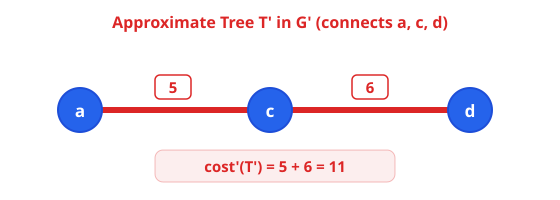

In [23]:
# SVG 4: Approximate Tree T' in G'
svg4 = wrap_svg('''
<text x="280" y="28" font-size="16" fill="#dc2626" text-anchor="middle" font-weight="700">Approximate Tree T' in G' (connects a, c, d)</text>

<line x1="80" y1="110" x2="270" y2="110" stroke="#dc2626" stroke-width="6" stroke-linecap="round"/>
<line x1="270" y1="110" x2="470" y2="110" stroke="#dc2626" stroke-width="6" stroke-linecap="round"/>

<rect x="155" y="75" width="36" height="24" rx="5" fill="#fff" stroke="#dc2626" stroke-width="1.5"/>
<text x="173" y="93" font-size="15" fill="#dc2626" text-anchor="middle" font-weight="700">5</text>
<rect x="352" y="75" width="36" height="24" rx="5" fill="#fff" stroke="#dc2626" stroke-width="1.5"/>
<text x="370" y="93" font-size="15" fill="#dc2626" text-anchor="middle" font-weight="700">6</text>

<circle cx="80"  cy="110" r="22" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="80"  y="117" font-size="17" fill="#fff" text-anchor="middle" font-weight="700">a</text>
<circle cx="270" cy="110" r="22" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="270" y="117" font-size="17" fill="#fff" text-anchor="middle" font-weight="700">c</text>
<circle cx="470" cy="110" r="22" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="470" y="117" font-size="17" fill="#fff" text-anchor="middle" font-weight="700">d</text>

<rect x="155" y="150" width="240" height="32" rx="8" fill="rgba(220,38,38,.08)" stroke="rgba(220,38,38,.3)"/>
<text x="275" y="172" font-size="15" fill="#dc2626" text-anchor="middle" font-weight="700">cost'(T') = 5 + 6 = 11</text>
''', 560, 200)

display(SVG(svg4))

### Step B: Replace Each Edge of T' by Its Shortest Path in G

| Edge in T' | cost' in G' | Replaced by path in G | Path cost | Edges used |
|------------|-------------|----------------------|-----------|------------|
| **(a, c)** | 5 | a -> b -> c | 3 + 2 = 5 | {a-b, b-c} |
| **(c, d)** | 6 | c -> b -> d | 2 + 4 = 6 | {c-b, b-d} |

**Union of all edges:**

{a-b(3), b-c(2)} union {c-b(2), b-d(4)} = {a-b(3), b-c(2), b-d(4)}

(duplicate b-c removed)

### SVG 5 — Edge Replacement (Mapping Back)

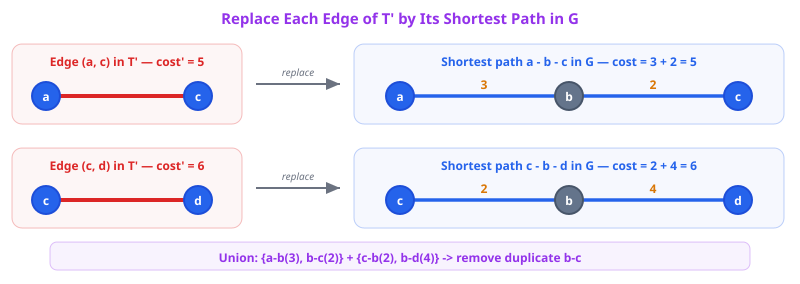

In [24]:
# SVG 5: Edge Replacement (Mapping Back)
defs5 = '<defs><marker id="a2" markerWidth="8" markerHeight="8" refX="7" refY="3" orient="auto"><path d="M0,0 L0,6 L7,3 z" fill="#6b7280"/></marker></defs>'

svg5 = wrap_svg('''
<text x="400" y="24" font-size="15" fill="#9333ea" text-anchor="middle" font-weight="700">Replace Each Edge of T' by Its Shortest Path in G</text>

<!-- Row 1: a-c -> a-b-c -->
<rect x="12" y="44" width="230" height="80" rx="10" fill="rgba(220,38,38,.04)" stroke="rgba(220,38,38,.3)"/>
<text x="127" y="66" font-size="12" fill="#dc2626" text-anchor="middle" font-weight="700">Edge (a, c) in T'  —  cost' = 5</text>
<line x1="46" y1="96" x2="198" y2="96" stroke="#dc2626" stroke-width="4" stroke-linecap="round"/>
<circle cx="46"  cy="96" r="14" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="46"  y="101" font-size="12" fill="#fff" text-anchor="middle" font-weight="700">a</text>
<circle cx="198" cy="96" r="14" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="198" y="101" font-size="12" fill="#fff" text-anchor="middle" font-weight="700">c</text>

<line x1="256" y1="84" x2="340" y2="84" stroke="#6b7280" stroke-width="2" marker-end="url(#a2)"/>
<text x="298" y="76" font-size="10" fill="#6b7280" text-anchor="middle" font-style="italic">replace</text>

<rect x="354" y="44" width="430" height="80" rx="10" fill="rgba(37,99,235,.04)" stroke="rgba(37,99,235,.3)"/>
<text x="569" y="66" font-size="12" fill="#2563eb" text-anchor="middle" font-weight="700">Shortest path a - b - c in G  —  cost = 3 + 2 = 5</text>
<line x1="400" y1="96" x2="569" y2="96" stroke="#2563eb" stroke-width="3.5" stroke-linecap="round"/>
<line x1="569" y1="96" x2="738" y2="96" stroke="#2563eb" stroke-width="3.5" stroke-linecap="round"/>
<circle cx="400" cy="96" r="14" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="400" y="101" font-size="12" fill="#fff" text-anchor="middle" font-weight="700">a</text>
<circle cx="569" cy="96" r="14" fill="#64748b" stroke="#475569" stroke-width="2"/>
<text   x="569" y="101" font-size="12" fill="#fff" text-anchor="middle" font-weight="700">b</text>
<circle cx="738" cy="96" r="14" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="738" y="101" font-size="12" fill="#fff" text-anchor="middle" font-weight="700">c</text>
<text x="484" y="89" font-size="12" fill="#d97706" text-anchor="middle" font-weight="700">3</text>
<text x="653" y="89" font-size="12" fill="#d97706" text-anchor="middle" font-weight="700">2</text>

<!-- Row 2: c-d -> c-b-d -->
<rect x="12" y="148" width="230" height="80" rx="10" fill="rgba(220,38,38,.04)" stroke="rgba(220,38,38,.3)"/>
<text x="127" y="170" font-size="12" fill="#dc2626" text-anchor="middle" font-weight="700">Edge (c, d) in T'  —  cost' = 6</text>
<line x1="46" y1="200" x2="198" y2="200" stroke="#dc2626" stroke-width="4" stroke-linecap="round"/>
<circle cx="46"  cy="200" r="14" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="46"  y="205" font-size="12" fill="#fff" text-anchor="middle" font-weight="700">c</text>
<circle cx="198" cy="200" r="14" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="198" y="205" font-size="12" fill="#fff" text-anchor="middle" font-weight="700">d</text>

<line x1="256" y1="188" x2="340" y2="188" stroke="#6b7280" stroke-width="2" marker-end="url(#a2)"/>
<text x="298" y="180" font-size="10" fill="#6b7280" text-anchor="middle" font-style="italic">replace</text>

<rect x="354" y="148" width="430" height="80" rx="10" fill="rgba(37,99,235,.04)" stroke="rgba(37,99,235,.3)"/>
<text x="569" y="170" font-size="12" fill="#2563eb" text-anchor="middle" font-weight="700">Shortest path c - b - d in G  —  cost = 2 + 4 = 6</text>
<line x1="400" y1="200" x2="569" y2="200" stroke="#2563eb" stroke-width="3.5" stroke-linecap="round"/>
<line x1="569" y1="200" x2="738" y2="200" stroke="#2563eb" stroke-width="3.5" stroke-linecap="round"/>
<circle cx="400" cy="200" r="14" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="400" y="205" font-size="12" fill="#fff" text-anchor="middle" font-weight="700">c</text>
<circle cx="569" cy="200" r="14" fill="#64748b" stroke="#475569" stroke-width="2"/>
<text   x="569" y="205" font-size="12" fill="#fff" text-anchor="middle" font-weight="700">b</text>
<circle cx="738" cy="200" r="14" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="738" y="205" font-size="12" fill="#fff" text-anchor="middle" font-weight="700">d</text>
<text x="484" y="193" font-size="12" fill="#d97706" text-anchor="middle" font-weight="700">2</text>
<text x="653" y="193" font-size="12" fill="#d97706" text-anchor="middle" font-weight="700">4</text>

<!-- Bottom note -->
<rect x="50" y="242" width="700" height="28" rx="7" fill="rgba(147,51,234,.06)" stroke="rgba(147,51,234,.3)"/>
<text x="400" y="262" font-size="12" fill="#9333ea" text-anchor="middle" font-weight="700">Union: {a-b(3), b-c(2)} + {c-b(2), b-d(4)} -> remove duplicate b-c</text>
''', 800, 284, defs5)

display(SVG(svg5))

### Step C: Final Steiner Tree T in G

"All required vertices are connected. Remove duplicate edges / cycles to obtain tree T."

| Edge | Cost |
|------|------|
| a - b | **3** |
| b - c | **2** |
| b - d | **4** |

**Total cost(T) = 3 + 2 + 4 = 9**

cost(T) = 9 <= 11 = cost'(T')

$$\text{cost}(T) \leq \text{cost}'(T')$$

### SVG 6 — Final Steiner Tree T

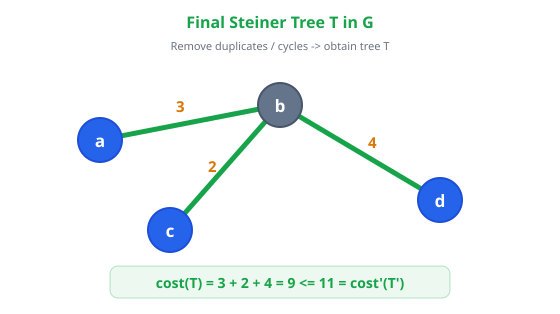

In [25]:
# SVG 6: Final Steiner Tree T in G
svg6 = wrap_svg('''
<text x="280" y="28" font-size="16" fill="#16a34a" text-anchor="middle" font-weight="700">Final Steiner Tree T in G</text>
<text x="280" y="50" font-size="11" fill="#6b7280" text-anchor="middle">Remove duplicates / cycles -> obtain tree T</text>

<line x1="100" y1="140" x2="280" y2="105" stroke="#16a34a" stroke-width="5" stroke-linecap="round"/>
<line x1="280" y1="105" x2="170" y2="230" stroke="#16a34a" stroke-width="5" stroke-linecap="round"/>
<line x1="280" y1="105" x2="440" y2="200" stroke="#16a34a" stroke-width="5" stroke-linecap="round"/>

<text x="176" y="112" font-size="15" fill="#d97706" font-weight="700">3</text>
<text x="208" y="172" font-size="15" fill="#d97706" font-weight="700">2</text>
<text x="368" y="148" font-size="15" fill="#d97706" font-weight="700">4</text>

<circle cx="100" cy="140" r="22" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="100" y="147" font-size="17" fill="#fff" text-anchor="middle" font-weight="700">a</text>
<circle cx="280" cy="105" r="22" fill="#64748b" stroke="#475569" stroke-width="2"/>
<text   x="280" y="112" font-size="17" fill="#fff" text-anchor="middle" font-weight="700">b</text>
<circle cx="170" cy="230" r="22" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="170" y="237" font-size="17" fill="#fff" text-anchor="middle" font-weight="700">c</text>
<circle cx="440" cy="200" r="22" fill="#2563eb" stroke="#1d4ed8" stroke-width="2"/>
<text   x="440" y="207" font-size="17" fill="#fff" text-anchor="middle" font-weight="700">d</text>

<rect x="110" y="266" width="340" height="32" rx="8" fill="rgba(22,163,74,.08)" stroke="rgba(22,163,74,.3)"/>
<text x="280" y="288" font-size="14" fill="#16a34a" text-anchor="middle" font-weight="700">cost(T) = 3 + 2 + 4 = 9  &lt;=  11 = cost'(T')</text>
''', 560, 314)

display(SVG(svg6))

---

## 5. Conclusion — Factor-Preserving Reduction

### The Reduction Pipeline: I -> I' -> T' -> T

| Step | Input | Output | Operation | Time |
|------|-------|--------|-----------|------|
| 1 | Instance I (Graph G) | Instance I' (Graph G') | Compute metric closure (all-pairs shortest paths) | Polynomial |
| 2 | Instance I' (Metric Graph G') | Approx Tree T' | Run alpha-approximation for metric Steiner tree | Depends on alg. |
| 3 | Tree T' in G' | Tree T in G | Replace edges by shortest paths, remove duplicates | Polynomial |

### The Chain of Inequalities

cost(T)

  <= cost'(T') &nbsp;&nbsp;&nbsp;&nbsp; *(mapping back: replacing edges by paths can only reduce cost)*

  <= alpha * OPT(I') &nbsp;&nbsp;&nbsp;&nbsp; *(T' is an alpha-approximation in G')*

  <= alpha * OPT(I) &nbsp;&nbsp;&nbsp;&nbsp; *(lower bound: OPT(I') <= OPT(I))*

$$\text{cost}(T) \;\leq\; \text{cost}'(T') \;\leq\; \alpha \cdot OPT(I') \;\leq\; \alpha \cdot OPT(I)$$

### Numerical Verification

| Quantity | Value | Relation |
|----------|-------|----------|
| cost(T) | **9** | 9 <= 11 |
| cost'(T') | **11** | 11 <= alpha * 9 |
| OPT(I') | **9** | OPT(I') = 9 <= 9 = OPT(I) |
| OPT(I) | **9** | |

**Full chain:** 9 <= 11 <= alpha * 9 <= alpha * 9

### SVG 7 — Reduction Pipeline

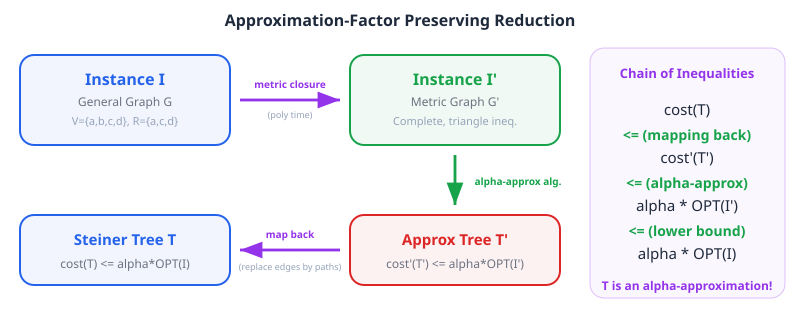

In [26]:
# SVG 7: Reduction Pipeline + Chain of Inequalities
defs7 = '''<defs>
<marker id="a4" markerWidth="9" markerHeight="9" refX="8" refY="3" orient="auto"><path d="M0,0 L0,6 L8,3 z" fill="#9333ea"/></marker>
<marker id="a5" markerWidth="9" markerHeight="9" refX="8" refY="3" orient="auto"><path d="M0,0 L0,6 L8,3 z" fill="#16a34a"/></marker>
</defs>'''

svg7 = wrap_svg('''
<text x="400" y="26" font-size="16" fill="#1e293b" text-anchor="middle" font-weight="700">Approximation-Factor Preserving Reduction</text>

<!-- Box I -->
<rect x="20" y="55" width="210" height="90" rx="14" fill="rgba(37,99,235,.06)" stroke="#2563eb" stroke-width="2"/>
<text x="125" y="85" font-size="16" fill="#2563eb" text-anchor="middle" font-weight="700">Instance I</text>
<text x="125" y="106" font-size="12" fill="#6b7280" text-anchor="middle">General Graph G</text>
<text x="125" y="125" font-size="11" fill="#94a3b8" text-anchor="middle">V={a,b,c,d}, R={a,c,d}</text>

<!-- Arrow right -->
<line x1="240" y1="100" x2="340" y2="100" stroke="#9333ea" stroke-width="2.8" marker-end="url(#a4)"/>
<text x="290" y="88" font-size="10" fill="#9333ea" text-anchor="middle" font-weight="700">metric closure</text>
<text x="290" y="118" font-size="9" fill="#94a3b8" text-anchor="middle">(poly time)</text>

<!-- Box I' -->
<rect x="350" y="55" width="210" height="90" rx="14" fill="rgba(22,163,74,.06)" stroke="#16a34a" stroke-width="2"/>
<text x="455" y="85" font-size="16" fill="#16a34a" text-anchor="middle" font-weight="700">Instance I'</text>
<text x="455" y="106" font-size="12" fill="#6b7280" text-anchor="middle">Metric Graph G'</text>
<text x="455" y="125" font-size="11" fill="#94a3b8" text-anchor="middle">Complete, triangle ineq.</text>

<!-- Arrow down -->
<line x1="455" y1="155" x2="455" y2="205" stroke="#16a34a" stroke-width="2.8" marker-end="url(#a5)"/>
<text x="518" y="185" font-size="10" fill="#16a34a" text-anchor="middle" font-weight="700">alpha-approx alg.</text>

<!-- Box T' -->
<rect x="350" y="215" width="210" height="70" rx="14" fill="rgba(220,38,38,.06)" stroke="#dc2626" stroke-width="2"/>
<text x="455" y="245" font-size="15" fill="#dc2626" text-anchor="middle" font-weight="700">Approx Tree T'</text>
<text x="455" y="268" font-size="12" fill="#6b7280" text-anchor="middle">cost'(T') &lt;= alpha*OPT(I')</text>

<!-- Arrow left -->
<line x1="340" y1="250" x2="240" y2="250" stroke="#9333ea" stroke-width="2.8" marker-end="url(#a4)"/>
<text x="290" y="238" font-size="10" fill="#9333ea" text-anchor="middle" font-weight="700">map back</text>
<text x="290" y="270" font-size="9" fill="#94a3b8" text-anchor="middle">(replace edges by paths)</text>

<!-- Box T -->
<rect x="20" y="215" width="210" height="70" rx="14" fill="rgba(37,99,235,.06)" stroke="#2563eb" stroke-width="2"/>
<text x="125" y="245" font-size="15" fill="#2563eb" text-anchor="middle" font-weight="700">Steiner Tree T</text>
<text x="125" y="268" font-size="12" fill="#6b7280" text-anchor="middle">cost(T) &lt;= alpha*OPT(I)</text>

<!-- Chain of inequalities -->
<rect x="590" y="48" width="195" height="250" rx="14" fill="rgba(147,51,234,.04)" stroke="rgba(147,51,234,.3)"/>
<text x="687" y="78" font-size="13" fill="#9333ea" text-anchor="middle" font-weight="700">Chain of Inequalities</text>

<text x="687" y="115" font-size="15" fill="#1e293b" text-anchor="middle">cost(T)</text>
<text x="687" y="140" font-size="14" fill="#16a34a" text-anchor="middle" font-weight="700">&lt;=  (mapping back)</text>
<text x="687" y="163" font-size="15" fill="#1e293b" text-anchor="middle">cost'(T')</text>
<text x="687" y="188" font-size="14" fill="#16a34a" text-anchor="middle" font-weight="700">&lt;=  (alpha-approx)</text>
<text x="687" y="211" font-size="15" fill="#1e293b" text-anchor="middle">alpha * OPT(I')</text>
<text x="687" y="236" font-size="14" fill="#16a34a" text-anchor="middle" font-weight="700">&lt;=  (lower bound)</text>
<text x="687" y="259" font-size="15" fill="#1e293b" text-anchor="middle">alpha * OPT(I)</text>

<text x="687" y="290" font-size="12" fill="#9333ea" text-anchor="middle" font-weight="700">T is an alpha-approximation!</text>
''', 800, 310, defs7)

display(SVG(svg7))

---

## 6. Theorem 3.2 (Vazirani)

**Statement:** The reduction from the Steiner tree problem to the metric Steiner tree problem is approximation factor preserving.

**Consequence:** Any approximation factor established for the metric Steiner tree problem carries over to the general Steiner tree problem.

**If** there exists an $\alpha$-approximation algorithm for the metric Steiner tree problem,
**then** there exists an $\alpha$-approximation algorithm for the general Steiner tree problem. $\blacksquare$

---

## 7. Quick-Copy Reference

### Key Formulas (LaTeX)

| Description | Formula | LaTeX Code |
|-------------|---------|------------|
| Metric closure | cost'(u,v) = dist_G(u,v) | `\text{cost}'(u,v) = \text{dist}_G(u,v)` |
| Lower bound | OPT(I') <= OPT(I) | `OPT(I') \leq OPT(I)` |
| Mapping back | cost(T) <= cost'(T') | `\text{cost}(T) \leq \text{cost}'(T')` |
| alpha-approximation | cost'(T') <= alpha * OPT(I') | `\text{cost}'(T') \leq \alpha \cdot OPT(I')` |
| Full chain | cost(T) <= cost'(T') <= alpha*OPT(I') <= alpha*OPT(I) | `\text{cost}(T) \leq \text{cost}'(T') \leq \alpha \cdot OPT(I') \leq \alpha \cdot OPT(I)` |
| Triangle ineq. | cost'(u,w) <= cost'(u,v) + cost'(v,w) | `\text{cost}'(u,w) \leq \text{cost}'(u,v) + \text{cost}'(v,w)` |

### All Numbers at a Glance

| Item | Value |
|------|-------|
| \|V\| | 4 |
| \|R\| | 3 |
| \|E\| in G | 5 |
| \|E\| in G' (complete) | 6 |
| Edge costs in G | a-b: 3, b-c: 2, b-d: 4, a-c: 7, c-d: 8 |
| Edge costs in G' | a-b: 3, a-c: 5, a-d: 7, b-c: 2, b-d: 4, c-d: 6 |
| OPT(I) = OPT in G | 9 (edges: a-b, b-c, b-d) |
| OPT(I') = OPT in G' | 9 |
| Approx T' in G' | 11 (edges: a-c, c-d) |
| Mapped tree T in G | 9 (edges: a-b, b-c, b-d) |

In [27]:
# Export all SVGs as white-background files for PowerPoint
import os

svg_dir = os.path.join(os.getcwd(), "svgs_white")
os.makedirs(svg_dir, exist_ok=True)

files = {
    "01_original_graph_G.svg": svg1,
    "02_G_to_metric_closure_G_prime.svg": svg2,
    "03_lower_bound_OPT.svg": svg3,
    "04_approx_tree_T_prime.svg": svg4,
    "05_edge_replacement_mapping_back.svg": svg5,
    "06_final_steiner_tree_T.svg": svg6,
    "07_reduction_pipeline.svg": svg7,
}

# Add XML header for standalone SVG files
for name, content in files.items():
    full = '<?xml version="1.0" encoding="UTF-8"?>\n' + content
    path = os.path.join(svg_dir, name)
    with open(path, "w", encoding="utf-8") as f:
        f.write(full)
    print(f"  Saved: {name}")

print(f"\nDone! {len(files)} white-background SVG files in:\n  {svg_dir}")
print("\nPowerPoint: Insert -> Pictures -> select .svg file")

  Saved: 01_original_graph_G.svg
  Saved: 02_G_to_metric_closure_G_prime.svg
  Saved: 03_lower_bound_OPT.svg
  Saved: 04_approx_tree_T_prime.svg
  Saved: 05_edge_replacement_mapping_back.svg
  Saved: 06_final_steiner_tree_T.svg
  Saved: 07_reduction_pipeline.svg

Done! 7 white-background SVG files in:
  c:\Users\as\Desktop\Unterricht\Seminar- Algorithm Seminar 2 Approximation Algorithms\Seminar Presentation Python\svgs_white

PowerPoint: Insert -> Pictures -> select .svg file
